In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import expon

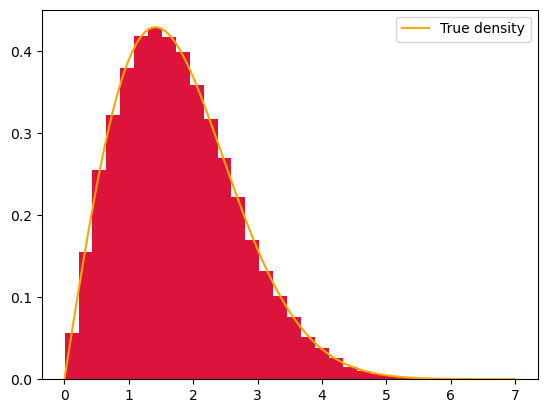

In [3]:
def quantile(u, theta):
    return np.sqrt(-theta**2 * np.log(1-u))

def density(x, theta):
    return (2*x/theta**2) * np.exp(-x**2/(theta**2)) 

np.random.seed(33)
theta = 2 
uniforms = np.random.uniform(0, 1, 100000)
x_axis = np.asarray(np.linspace(0, 7, 100000))
samples_1 = quantile(uniforms, theta)


plt.hist(samples_1, bins=30, color='crimson', density=True)
plt.plot(x_axis, density(x_axis, theta), '-', color="orange", label='True density')
plt.legend()
plt.show()


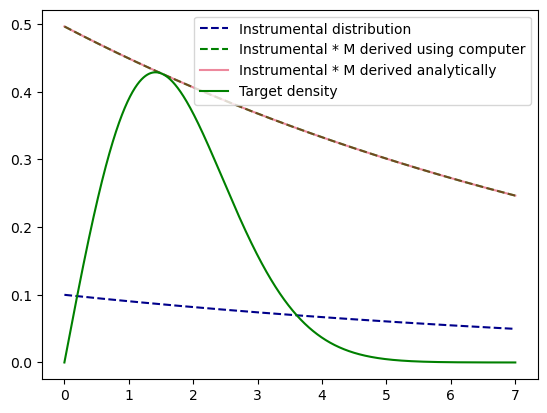

[]
[]


In [19]:

rate = 0.1
def ratio(x):
    return density(x, theta) / expon.pdf(x, scale = 1 / rate)

M_computer = np.max(ratio(x_axis))
analytic_max_x = 0.1 + np.sqrt(2.01)
M_analytic = ratio(analytic_max_x)
plt.plot(x_axis, expon.pdf(x_axis, scale = 1 / rate), '--',color='darkblue',  label='Instrumental distribution')
plt.plot(x_axis, M_computer * expon.pdf(x_axis, scale = 1 / rate), '--',color='green' , alpha = 1, label='Instrumental * M derived using computer')
plt.plot(x_axis, M_analytic * expon.pdf(x_axis, scale = 1 / rate), '-', color='crimson', alpha = 0.5, label = 'Instrumental * M derived analytically')
plt.plot(x_axis, density(x_axis, theta), color='green', label='Target density')


plt.legend();plt.show() 
envelope = M_computer * expon.pdf(x_axis, scale=1/rate)
violations = np.where(envelope < density(x_axis, theta))[0]
print(violations)   
envelope = M_analytic * expon.pdf(x_axis, scale=1/rate)
violations = np.where(envelope < density(x_axis, theta))[0]
print(violations) 



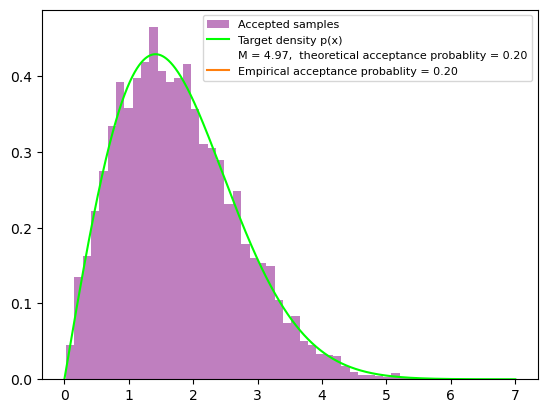

In [ ]:
def exp_inv(u):
    return -np.log(1-u) / rate

def acc_rej_ratio(x, M):
    return density(x, theta) / ( M * expon.pdf(x, scale = 1 / rate))




accepted_samples = 0
generated_candidates = 0
samples_2 = np.zeros(10000)
while accepted_samples < 10000:
    candidate = exp_inv(np.random.uniform())
    generated_candidates += 1
    ratio = acc_rej_ratio(candidate, M_analytic)
    uniform = np.random.uniform()
    if ratio >= uniform:
        samples_2[accepted_samples] = candidate 
        accepted_samples += 1


plt.hist(samples_2, bins = 50, alpha = 0.5, density=True, color='purple', label='Accepted samples')
plt.plot(x_axis, density(x_axis, theta), color='lime', label='Target density p(x)')
plt.plot([], [], ' ', label=f'M = {M_analytic:.2f},  theoretical acceptance probablity = {1/M_analytic:.2f}')
plt.plot([], [], '', label=f'Empirical acceptance probablity = {accepted_samples / generated_candidates:.2f}')
plt.legend()

plt.legend(fontsize=8,loc='upper right'); plt.show()





/var/folders/jp/s6km5b592j32vjlqzyq56c000000gn/T/ipykernel_31465/2331448437.py:13: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k--" (-> color='k'). The keyword argument will take precedence.
  plt.plot(x_grid, F_hat, 'k--', alpha=1, color='crimson', label='Monte Carlo')


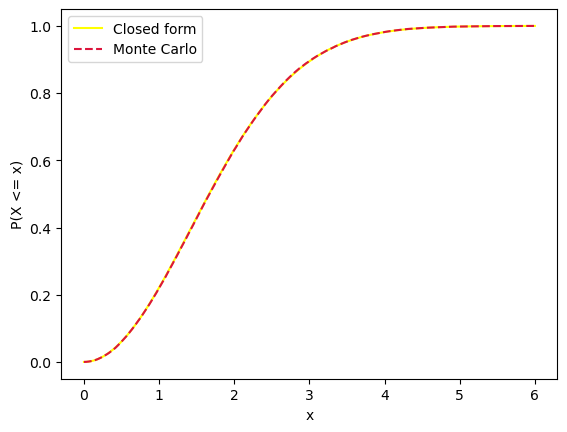

In [18]:
def true_cdf(x, theta=2):
    return 1 - np.exp(-x**2 / theta**2)

def cdf_mc(x, samples):
    """Monte Carlo approximation of P(X <= x) for each x in the array x."""
    return np.array([np.mean(samples <= xi) for xi in x])

x_grid = np.linspace(0, 6, 200)
F_hat = cdf_mc(x_grid, samples_1)          
F_true = true_cdf(x_grid, theta)

plt.plot(x_grid, F_true, color='yellow', label='Closed form')
plt.plot(x_grid, F_hat, 'k--', alpha=1, color='crimson', label='Monte Carlo')
plt.xlabel('x'); plt.ylabel('P(X <= x)')
plt.legend(); plt.show()


